# Member 1 — End-to-End Credit Card Fraud Data Pipeline

**Role:** Data Foundation, Exploratory Data Analysis (EDA), Row-Level Feature Engineering, and Leak-Free Dataset Generation  
**Primary Evaluation Metric:** Area Under the Precision-Recall Curve (**AUPRC** — `sklearn.metrics.average_precision_score`)

### Pipeline Architecture
1. **Section 1 — Setup & Validation Foundation:** Schema verification, unified Stratified 5-Fold Cross-Validation (`train_folds.csv`), and shared `evaluate_auprc` metric helper.
2. **Section 2 — Exploratory Data Analysis (EDA):** Class imbalance profile, missing-value audit, conditional feature distributions (`is_fraud = 0` vs `1`), categorical/risk-flag fraud rates, and numeric correlation matrix.
3. **Section 3 — Row-Level Feature Engineering:** Deterministic transaction-level financial ratios, behavioral velocity indicators, cyclical time encodings, and composite risk flags (`build_features`).
4. **Section 4 — Leak-Free Preprocessing & Dual Pipeline Setup:**
   - **Branch 1 (Member 2 — LightGBM):** Native scale + synchronized Pandas `category` dtypes (`processed_data/train_lgbm.parquet`, `processed_data/test_lgbm.parquet`).
   - **Branch 2 (Member 3 — Neural Network):** Lightweight shared module (`nn_data_pipeline.py` via `%%writefile`) operating directly on `train_folds.csv` and `test.csv` to perform strict fold-by-fold imputation, `log1p` skewness reduction, `RobustScaler`, and `OneHotEncoder` fit exclusively on `fold != k` (avoiding >100 MB duplicated fold files).
5. **Section 5 — Sanity Check & Quality Assurance:** Verification of feature counts, finite values (`NaN`/`Inf`-free), and strict `id` & `fold` alignment between `train_lgbm.parquet` and the `train_folds.csv` Neural Network fold loader.

---
## Section 1: Setup & Validation Foundation (Stratified 5-Fold CV)

In [1]:
import os, sys
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
N_SPLITS = 5
OUTPUT_DIR = "processed_data"

# Canonical column definitions (24 raw input features)
ID_COL = "id"
TARGET_COL = "is_fraud"

CONT_COLS = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "merchant_risk_score",
    "prior_disputes",
]

TIME_COLS = [
    "time_of_day_hour",
    "day_of_week",
]

CAT_COLS = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type",
]

RISK_FLAG_COLS = [
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
]

RAW_FEATURE_COLS = CONT_COLS + TIME_COLS + CAT_COLS + RISK_FLAG_COLS
assert len(RAW_FEATURE_COLS) == 24, f"Expected 24 raw features, got {len(RAW_FEATURE_COLS)}"
print(f"Configured {len(RAW_FEATURE_COLS)} raw input features across 4 semantic groups.")

Configured 24 raw input features across 4 semantic groups.


In [2]:
# Load raw datasets and verify schema integrity
train_raw = pd.read_csv("train.csv")
test_raw = pd.read_csv("test.csv")

print(f"Train shape : {train_raw.shape[0]:,} rows x {train_raw.shape[1]} columns")
print(f"Test shape  : {test_raw.shape[0]:,} rows x {test_raw.shape[1]} columns\n")

# Integrity assertions: column presence, unique IDs, non-null binary target
assert set([ID_COL, TARGET_COL] + RAW_FEATURE_COLS).issubset(train_raw.columns), "Missing columns in train.csv"
assert set([ID_COL] + RAW_FEATURE_COLS).issubset(test_raw.columns), "Missing columns in test.csv"
assert train_raw[ID_COL].is_unique, "Duplicate IDs detected in train.csv!"
assert test_raw[ID_COL].is_unique, "Duplicate IDs detected in test.csv!"
assert len(set(train_raw[ID_COL]).intersection(set(test_raw[ID_COL]))) == 0, "ID overlap between train and test!"
assert train_raw[TARGET_COL].isnull().sum() == 0, "Target column 'is_fraud' contains null values!"

# Standardize target dtype to integer (0 = normal, 1 = fraud)
train_raw[TARGET_COL] = train_raw[TARGET_COL].astype(int)
assert set(train_raw[TARGET_COL].unique()) == {0, 1}, "Target column 'is_fraud' must contain only {0, 1}"

schema_summary = pd.DataFrame({
    "train_dtype": train_raw.dtypes.astype(str),
    "test_dtype": test_raw.dtypes.reindex(train_raw.columns).fillna("N/A (Target)").astype(str),
})
print("Schema & Integrity Checks PASSED (Unique IDs, Zero Null Targets).")
display(schema_summary.T)

Train shape : 699,960 rows x 26 columns
Test shape  : 299,984 rows x 25 columns

Schema & Integrity Checks PASSED (Unique IDs, Zero Null Targets).


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
train_dtype,int64,float64,float64,int64,float64,int64,int64,float64,int64,float64,...,str,str,str,bool,bool,bool,bool,bool,bool,int64
test_dtype,int64,float64,float64,int64,float64,int64,int64,float64,int64,float64,...,str,str,str,bool,bool,bool,bool,bool,bool,N/A (Target)


In [3]:
# Create fixed Stratified 5-Fold split and shared AUPRC evaluation function
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
train_folds = train_raw.copy()
train_folds["fold"] = -1

for fold_idx, (_, val_idx) in enumerate(skf.split(train_folds, train_folds[TARGET_COL])):
    train_folds.iloc[val_idx, train_folds.columns.get_loc("fold")] = fold_idx

assert (train_folds["fold"] >= 0).all(), "Unassigned fold indices detected!"

fold_stats = (
    train_folds.groupby("fold")[TARGET_COL]
    .agg(
        total_samples="count",
        normal_count=lambda s: int((s == 0).sum()),
        fraud_count="sum",
        fraud_rate_pct=lambda s: round(s.mean() * 100, 4),
    )
    .reset_index()
)
print("Stratified 5-Fold Distribution Summary:")
display(fold_stats)

# Persist canonical fold-assigned training dataset for team-wide synchronization
train_folds.to_csv("train_folds.csv", index=False)
print("Saved canonical validation split to 'train_folds.csv'.")


def evaluate_auprc(y_true, y_pred_proba) -> float:
    """Shared primary evaluation metric (Area Under the Precision-Recall Curve)."""
    y_true_arr = np.asarray(y_true, dtype=np.int64)
    y_prob_arr = np.asarray(y_pred_proba, dtype=np.float64)
    if np.isnan(y_prob_arr).any() or np.isinf(y_prob_arr).any():
        raise ValueError("Predicted probabilities contain NaN or Inf values.")
    return float(average_precision_score(y_true_arr, y_prob_arr))


baseline_prior_auprc = evaluate_auprc(
    train_folds[TARGET_COL],
    np.full(len(train_folds), train_folds[TARGET_COL].mean()),
)
print(f"Random/Prior Baseline AUPRC: {baseline_prior_auprc:.6f} (equals overall fraud prevalence)")

Stratified 5-Fold Distribution Summary:


,fold,total_samples,normal_count,fraud_count,fraud_rate_pct
0,0,139992,137655,2337,1.6694
1,1,139992,137654,2338,1.6701
2,2,139992,137654,2338,1.6701
3,3,139992,137654,2338,1.6701
4,4,139992,137654,2338,1.6701


Saved canonical validation split to 'train_folds.csv'.
Random/Prior Baseline AUPRC: 0.016700 (equals overall fraud prevalence)


---
## Section 2: Exploratory Data Analysis (EDA)

,Class,Count,Percentage (%)
0,Normal (0),688271,98.33
1,Fraud (1),11689,1.67


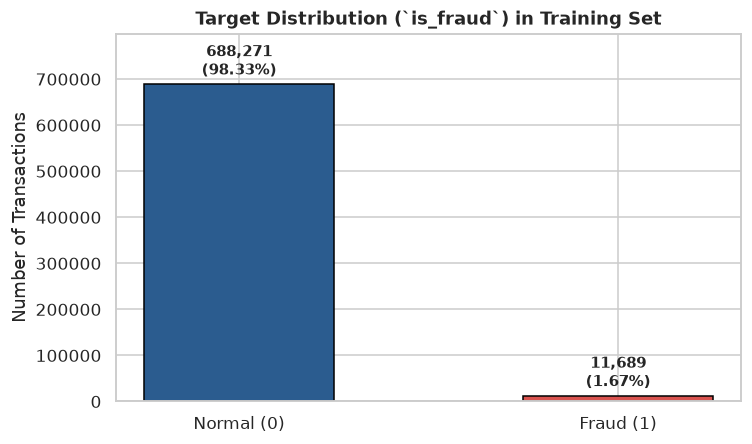

In [4]:
# 2.1 Target Class Imbalance Overview
train_df = pd.read_csv("train_folds.csv")
test_df = pd.read_csv("test.csv")

target_counts = train_df[TARGET_COL].value_counts().sort_index()
target_pcts = train_df[TARGET_COL].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Class": ["Normal (0)", "Fraud (1)"],
    "Count": target_counts.values,
    "Percentage (%)": target_pcts.round(4).values,
})
display(target_summary)

fig, ax = plt.subplots(figsize=(7, 4.2))
colors = ["#2b5c8f", "#d9534f"]
bars = ax.bar(target_summary["Class"], target_summary["Count"], color=colors, width=0.5, edgecolor="black")

for bar, cnt, pct in zip(bars, target_summary["Count"], target_summary["Percentage (%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + len(train_df) * 0.015,
        f"{cnt:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

ax.set_title("Target Distribution (`is_fraud`) in Training Set", fontsize=12, fontweight="bold")
ax.set_ylabel("Number of Transactions")
ax.set_ylim(0, target_summary["Count"].max() * 1.16)
plt.tight_layout()
plt.show()

In [5]:
# 2.2 Missing Values (%) Audit on train_folds.csv and test.csv
missing_report = pd.DataFrame({
    "train_missing_count": train_df.isnull().sum(),
    "train_missing_pct": (train_df.isnull().mean() * 100).round(4),
    "test_missing_count": test_df.isnull().sum().reindex(train_df.columns),
    "test_missing_pct": (test_df.isnull().mean() * 100).round(4).reindex(train_df.columns),
})

print(
    f"Columns with missing values -> Train: {(missing_report['train_missing_count'] > 0).sum()} | "
    f"Test: {(missing_report['test_missing_count'].fillna(0) > 0).sum()}"
)
display(missing_report)

Columns with missing values -> Train: 0 | Test: 0


,train_missing_count,train_missing_pct,test_missing_count,test_missing_pct
id,0,0.0,0.0,0.0
amount_usd,0,0.0,0.0,0.0
hours_since_last_txn,0,0.0,0.0,0.0
txn_count_last_24h,0,0.0,0.0,0.0
distance_from_home_km,0,0.0,0.0,0.0
card_age_months,0,0.0,0.0,0.0
customer_age,0,0.0,0.0,0.0
account_balance_usd,0,0.0,0.0,0.0
cvv_retry_count,0,0.0,0.0,0.0
velocity_score,0,0.0,0.0,0.0


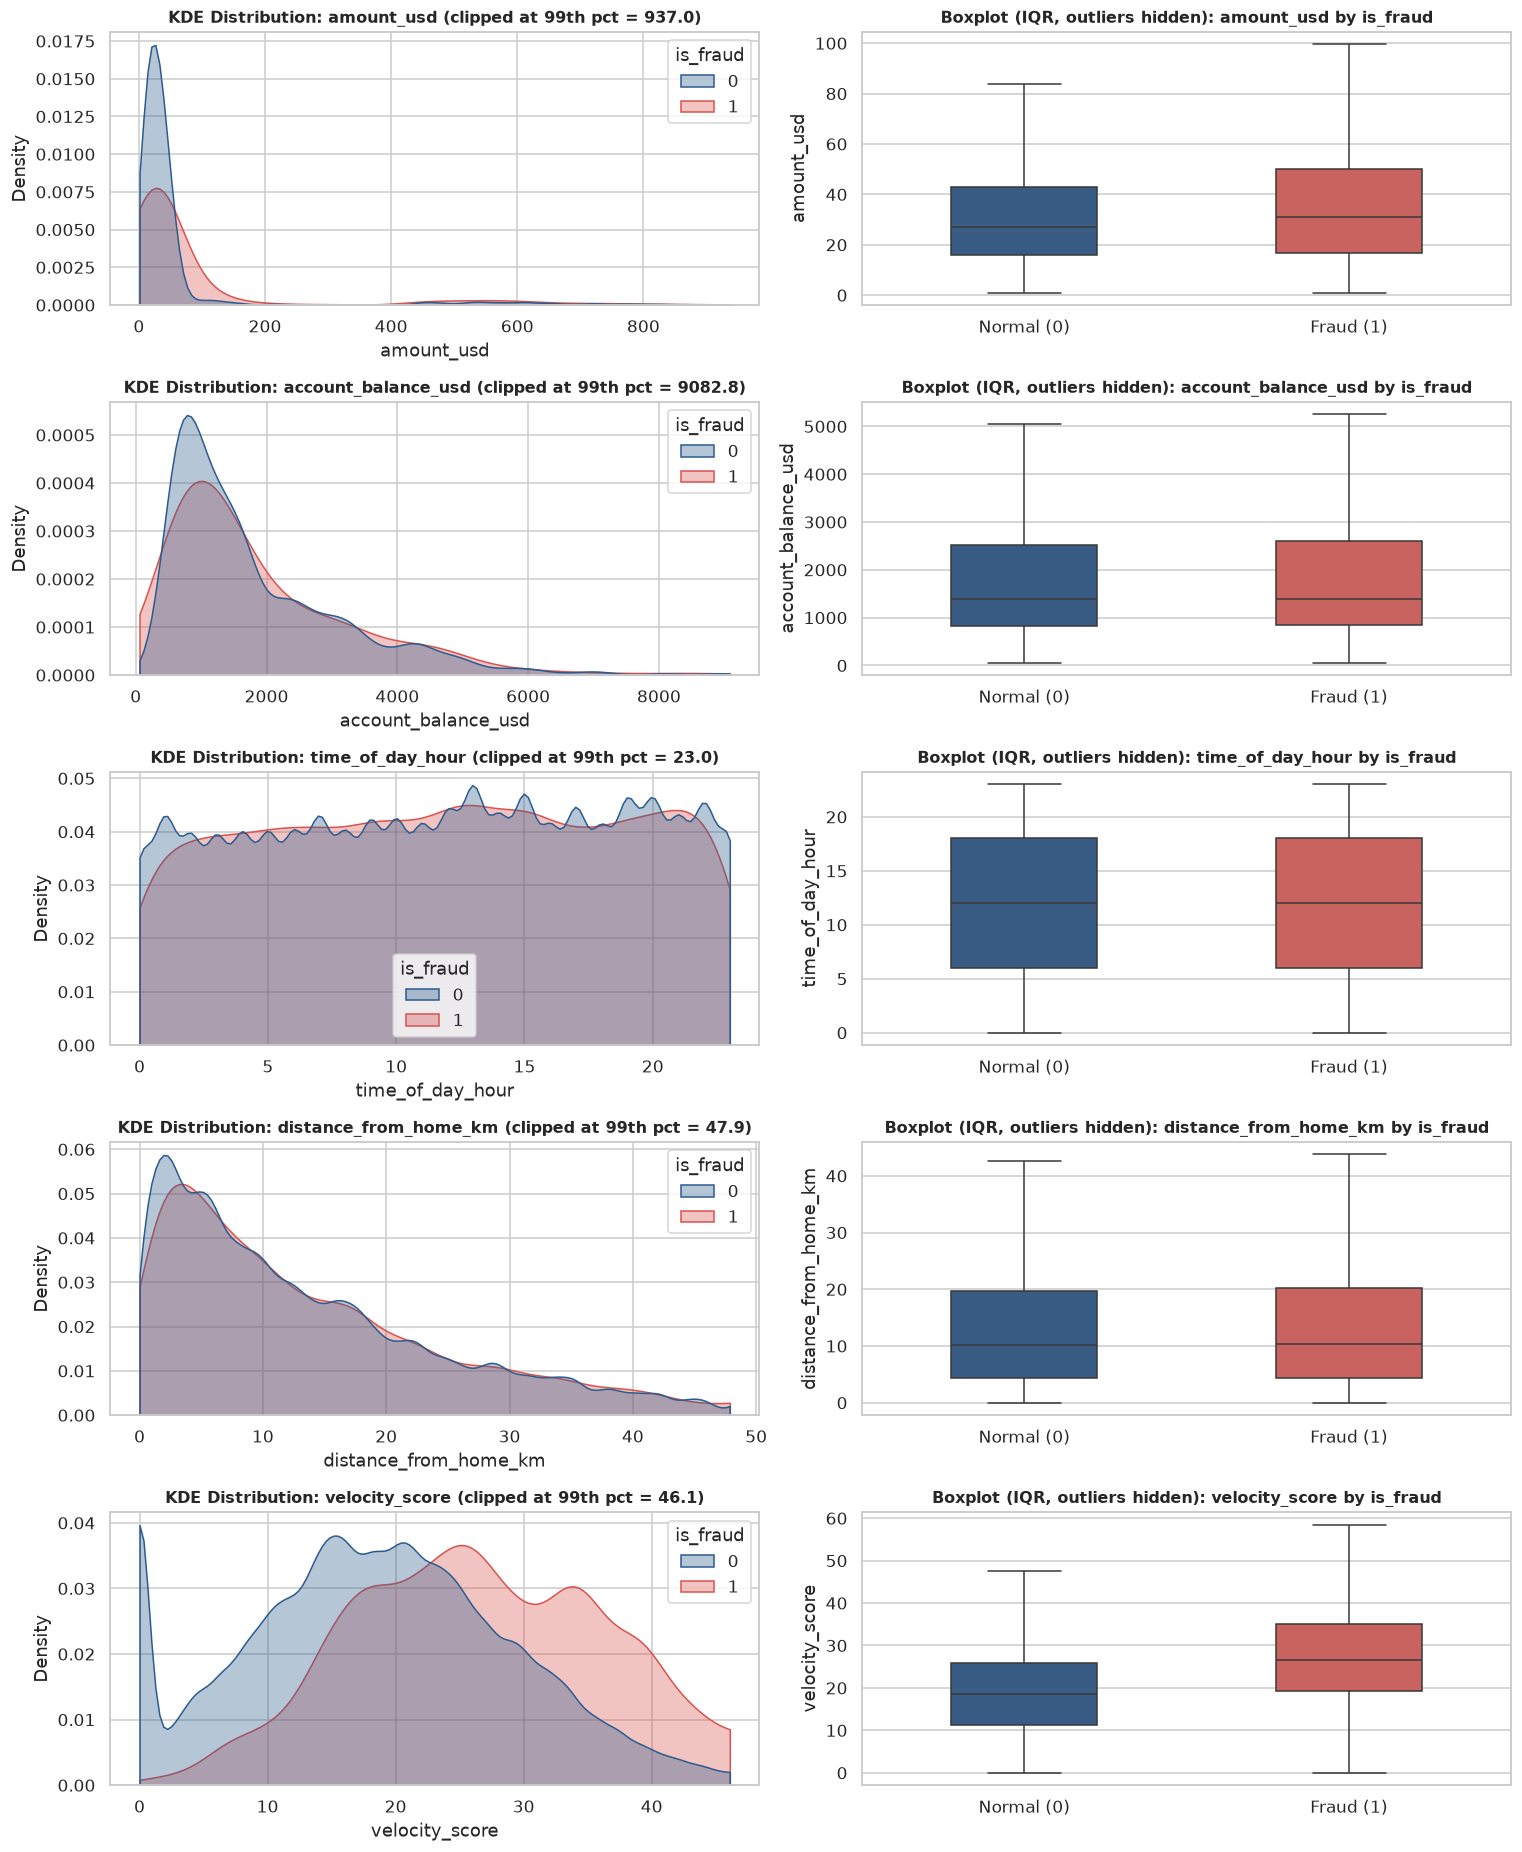

In [6]:
# 2.3 Conditional Numeric Distributions (KDE + Boxplot: Normal vs. Fraud)
key_num_cols = [
    "amount_usd",
    "account_balance_usd",
    "time_of_day_hour",
    "distance_from_home_km",
    "velocity_score",
]

fig, axes = plt.subplots(len(key_num_cols), 2, figsize=(14, 17))
palette_map = {0: "#2b5c8f", 1: "#d9534f"}

for row_idx, col in enumerate(key_num_cols):
    ax_kde, ax_box = axes[row_idx, 0], axes[row_idx, 1]
    upper_q99 = float(train_df[col].quantile(0.99))
    col_min = float(train_df[col].min())

    # Use common_norm=False so rare Fraud=1 density is directly comparable to Normal=0
    sns.kdeplot(
        data=train_df,
        x=col,
        hue=TARGET_COL,
        common_norm=False,
        fill=True,
        alpha=0.35,
        palette=palette_map,
        clip=(col_min, upper_q99),
        gridsize=150,
        ax=ax_kde,
    )
    ax_kde.set_title(f"KDE Distribution: {col} (clipped at 99th pct = {upper_q99:.1f})", fontsize=10.5, fontweight="bold")
    ax_kde.set_xlabel(col)
    ax_kde.set_ylabel("Density")

    sns.boxplot(
        data=train_df,
        x=TARGET_COL,
        y=col,
        hue=TARGET_COL,
        palette=palette_map,
        showfliers=False,
        legend=False,
        width=0.45,
        ax=ax_box,
    )
    ax_box.set_title(f"Boxplot (IQR, outliers hidden): {col} by is_fraud", fontsize=10.5, fontweight="bold")
    ax_box.set_xticks([0, 1])
    ax_box.set_xticklabels(["Normal (0)", "Fraud (1)"])
    ax_box.set_xlabel("")

plt.tight_layout()
plt.show()

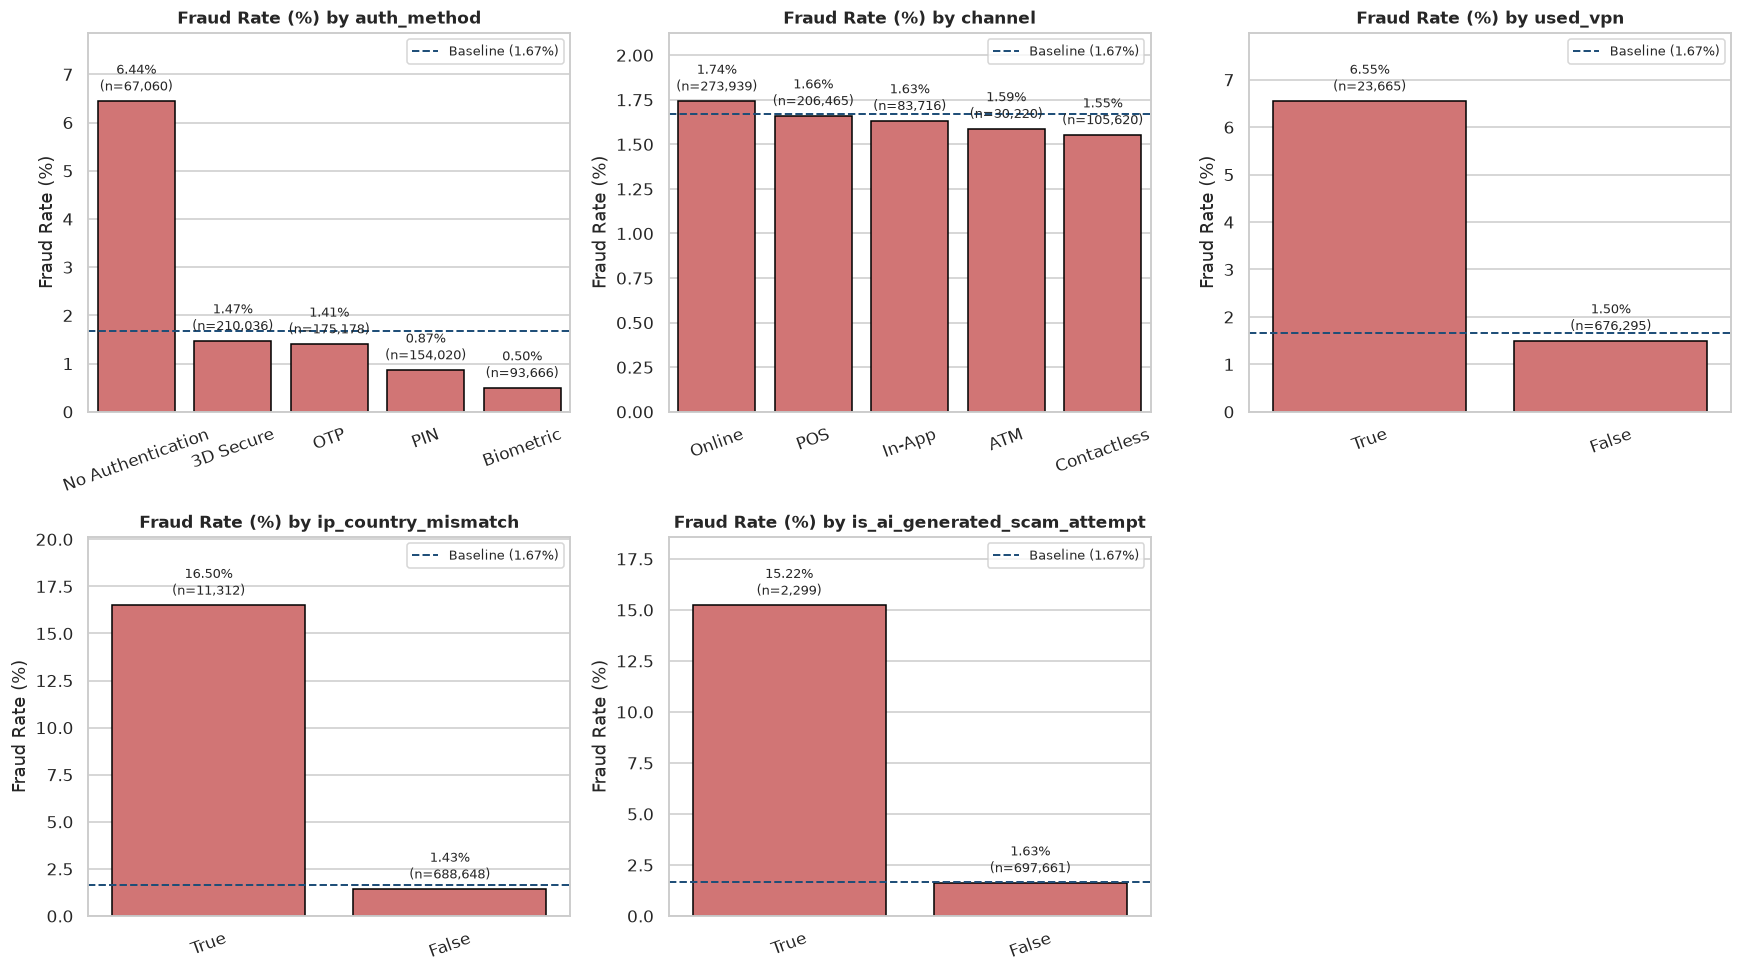

In [7]:
# 2.4 Fraud Rate (%) Across Key Categorical & Binary Risk Flag Variables
cat_risk_eda_cols = [
    "auth_method",
    "channel",
    "used_vpn",
    "ip_country_mismatch",
    "is_ai_generated_scam_attempt",
]

overall_fraud_pct = train_df[TARGET_COL].mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes_flat = axes.flatten()

for idx, col in enumerate(cat_risk_eda_cols):
    ax = axes_flat[idx]
    grp = (
        train_df.groupby(col, dropna=False)[TARGET_COL]
        .agg(count="count", fraud_rate_pct=lambda s: s.mean() * 100)
        .reset_index()
        .sort_values("fraud_rate_pct", ascending=False)
    )
    grp[col] = grp[col].astype(str)

    sns.barplot(
        data=grp,
        x=col,
        y="fraud_rate_pct",
        color="#e06666",
        edgecolor="black",
        ax=ax,
    )
    ax.axhline(overall_fraud_pct, color="#1f4e78", linestyle="--", linewidth=1.3, label=f"Baseline ({overall_fraud_pct:.2f}%)")
    ax.set_title(f"Fraud Rate (%) by {col}", fontsize=11, fontweight="bold")
    ax.set_ylabel("Fraud Rate (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, grp["fraud_rate_pct"].max() * 1.22)
    ax.legend(loc="upper right", fontsize=8.5)

    for patch, (_, row) in zip(ax.patches, grp.iterrows()):
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            patch.get_height() + grp["fraud_rate_pct"].max() * 0.02,
            f"{row['fraud_rate_pct']:.2f}%\n(n={int(row['count']):,})",
            ha="center",
            va="bottom",
            fontsize=8.5,
        )

axes_flat[-1].axis("off")
plt.tight_layout()
plt.show()

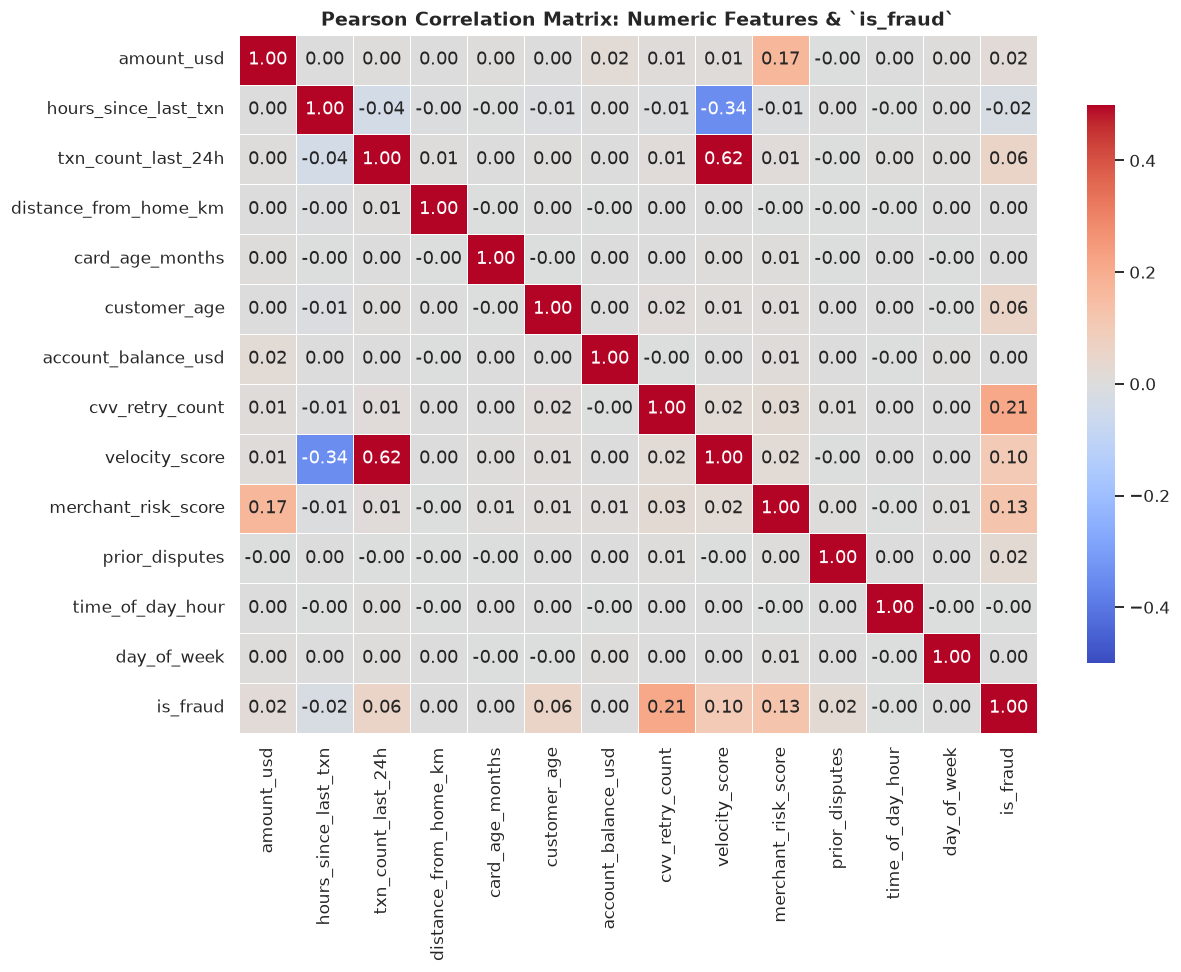

Top Absolute Linear Correlations with `is_fraud` (Numeric Features):


,pearson_corr_with_is_fraud
cvv_retry_count,0.212290
merchant_risk_score,0.125391
velocity_score,0.101650
txn_count_last_24h,0.058035
customer_age,0.056051
prior_disputes,0.023644
hours_since_last_txn,-0.020490
amount_usd,0.019443
day_of_week,0.003651
distance_from_home_km,0.001826


In [8]:
# 2.5 Correlation Matrix Heatmap Between Numeric Features and Target (is_fraud)
corr_cols = CONT_COLS + TIME_COLS + [TARGET_COL]
corr_matrix = train_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11.5, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-0.5,
    vmax=0.5,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Pearson Correlation Matrix: Numeric Features & `is_fraud`", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

print("Top Absolute Linear Correlations with `is_fraud` (Numeric Features):")
display(
    corr_matrix[TARGET_COL]
    .drop(TARGET_COL)
    .reindex(corr_matrix[TARGET_COL].drop(TARGET_COL).abs().sort_values(ascending=False).index)
    .to_frame(name="pearson_corr_with_is_fraud")
)

---
## Section 3: Row-Level Feature Engineering (`build_features`)

All transformations below are computed **strictly within each individual transaction row** (using zero cross-row statistics or target information), guaranteeing identical behavior on `train` and `test` with **zero Data Leakage**.

In [9]:
ENGINEERED_COLS = [
    # 1. Financial ratio features
    "amount_to_balance_ratio",
    "is_over_balance",
    "amount_per_txn_24h",
    # 2. Velocity & behavioral features
    "travel_speed_kmh",
    "is_brand_new_card",
    "has_cvv_retry",
    # 3. Temporal & aggregated risk features
    "hour_sin",
    "hour_cos",
    "is_night_txn",
    "is_weekend",
    "total_risk_flags",
]


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Generate deterministic row-level domain features identically for train and test."""
    out = df.copy()

    # Standardize original 6 binary risk flags to integer 0/1
    for flag_col in RISK_FLAG_COLS:
        if out[flag_col].isnull().any():
            out[flag_col] = out[flag_col].astype(float)
        else:
            out[flag_col] = out[flag_col].astype(int)

    # 1. Financial Ratio Features
    out["amount_to_balance_ratio"] = out["amount_usd"] / (out["account_balance_usd"] + 1e-5)
    out["is_over_balance"] = (out["amount_usd"] > out["account_balance_usd"]).astype(int)
    out["amount_per_txn_24h"] = out["amount_usd"] / (out["txn_count_last_24h"] + 1)

    # 2. Velocity & Behavioral Features
    out["travel_speed_kmh"] = out["distance_from_home_km"] / (out["hours_since_last_txn"] + 0.1)
    out["is_brand_new_card"] = (out["card_age_months"] <= 1).astype(int)
    out["has_cvv_retry"] = (out["cvv_retry_count"] > 0).astype(int)

    # 3. Temporal & Aggregated Risk Features
    out["hour_sin"] = np.sin(2.0 * np.pi * out["time_of_day_hour"] / 24.0)
    out["hour_cos"] = np.cos(2.0 * np.pi * out["time_of_day_hour"] / 24.0)
    out["is_night_txn"] = out["time_of_day_hour"].between(0, 5).astype(int)

    # Dynamic format detection for day_of_week -> is_weekend
    dow = out["day_of_week"]
    if pd.api.types.is_numeric_dtype(dow):
        dow_valid = dow.dropna()
        if len(dow_valid) > 0 and dow_valid.min() >= 1 and dow_valid.max() == 7:
            out["is_weekend"] = dow.isin([6, 7]).astype(int)
        else:  # 0-6 convention (0=Monday ... 5=Saturday, 6=Sunday)
            out["is_weekend"] = dow.isin([5, 6]).astype(int)
    else:
        weekend_strings = {
            "saturday", "sunday", "sat", "sun",
            "thứ 7", "thứ bảy", "chủ nhật", "thu 7", "thu bay", "chu nhat", "t7", "cn",
        }
        out["is_weekend"] = (
            dow.astype(str).str.strip().str.lower().isin(weekend_strings).astype(int)
        )

    out["total_risk_flags"] = out[RISK_FLAG_COLS].sum(axis=1)
    return out


train_fe = build_features(train_df)
test_fe = build_features(test_df)

ALL_FEATURE_COLS = RAW_FEATURE_COLS + ENGINEERED_COLS
print(f"Engineered {len(ENGINEERED_COLS)} new features -> Total features: {len(ALL_FEATURE_COLS)}")
display(train_fe[ENGINEERED_COLS].describe().T[["mean", "std", "min", "50%", "max"]])

Engineered 11 new features -> Total features: 35


,mean,std,min,50%,max
amount_to_balance_ratio,0.066704,0.205547,0.000028,1.854997e-02,14.609766
is_over_balance,0.010672,0.102753,0.000000,0.000000e+00,1.000000
amount_per_txn_24h,23.769279,68.932450,0.111111,7.190000e+00,5435.430000
travel_speed_kmh,6.538657,17.174483,0.000000,2.050682e+00,477.000000
is_brand_new_card,0.000000,0.000000,0.000000,0.000000e+00,0.000000
has_cvv_retry,0.082679,0.275397,0.000000,0.000000e+00,1.000000
hour_sin,-0.025513,0.705570,-1.000000,0.000000e+00,1.000000
hour_cos,-0.014472,0.708034,-1.000000,-1.836970e-16,1.000000
is_night_txn,0.234748,0.423841,0.000000,0.000000e+00,1.000000
is_weekend,0.279856,0.448929,0.000000,0.000000e+00,1.000000


---
## Section 4: Leak-Free Preprocessing & Dual Pipeline Setup

1. **Branch 1 — LightGBM (`Member 2`):** Original numerical scale preserved; 5 categorical columns cast to synchronized Pandas `category` dtype (`processed_data/train_lgbm.parquet`, `processed_data/test_lgbm.parquet`).
2. **Branch 2 — Neural Network (`Member 3`):** Exports a lightweight shared module (`nn_data_pipeline.py` via `%%writefile`) that reads directly from **`train_folds.csv`** and **`test.csv`** (auto-generating `train_folds.csv` from `train.csv` if missing) and runs strict per-fold preprocessing (`fold != k` fit -> `fold == k` & `test` transform) on demand, avoiding >100 MB serialized fold artifacts.

In [10]:
# 4.1 Branch 1 — Export Clean Datasets for Member 2 (LightGBM)
os.makedirs(OUTPUT_DIR, exist_ok=True)

train_lgbm = train_fe[[ID_COL, "fold", TARGET_COL] + ALL_FEATURE_COLS].copy()
test_lgbm = test_fe[[ID_COL] + ALL_FEATURE_COLS].copy()

# Synchronize Pandas category levels across train and test
for col in CAT_COLS:
    union_categories = sorted(
        pd.concat([train_lgbm[col], test_lgbm[col]], ignore_index=True)
        .dropna()
        .astype(str)
        .unique()
    )
    cat_dtype = pd.CategoricalDtype(categories=union_categories, ordered=False)
    train_lgbm[col] = train_lgbm[col].where(train_lgbm[col].notna(), None).astype(cat_dtype)
    test_lgbm[col] = test_lgbm[col].where(test_lgbm[col].notna(), None).astype(cat_dtype)

train_lgbm_path = os.path.join(OUTPUT_DIR, "train_lgbm.parquet")
test_lgbm_path = os.path.join(OUTPUT_DIR, "test_lgbm.parquet")

train_lgbm.to_parquet(train_lgbm_path, index=False)
test_lgbm.to_parquet(test_lgbm_path, index=False)

print(f"Saved LightGBM train : {train_lgbm_path} | shape={train_lgbm.shape}")
print(f"Saved LightGBM test  : {test_lgbm_path} | shape={test_lgbm.shape}")
print("Categorical dtypes verified:", {c: str(train_lgbm[c].dtype) for c in CAT_COLS})

Saved LightGBM train : processed_data/train_lgbm.parquet | shape=(699960, 38)
Saved LightGBM test  : processed_data/test_lgbm.parquet | shape=(299984, 36)
Categorical dtypes verified: {'merchant_category': 'category', 'card_type': 'category', 'auth_method': 'category', 'channel': 'category', 'device_type': 'category'}


In [11]:
%%writefile nn_data_pipeline.py
"""Leak-free fold-wise Neural Network data pipeline built directly from train_folds.csv."""

import os
from typing import Iterator
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, RobustScaler

SEED = 42
N_SPLITS = 5
ID_COL = "id"
TARGET_COL = "is_fraud"

CONT_COLS = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "merchant_risk_score",
    "prior_disputes",
]

TIME_COLS = ["time_of_day_hour", "day_of_week"]

CAT_COLS = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type",
]

RISK_FLAG_COLS = [
    "is_foreign_transaction",
    "is_new_merchant",
    "used_vpn",
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_ai_generated_scam_attempt",
]

ENGINEERED_COLS = [
    "amount_to_balance_ratio",
    "is_over_balance",
    "amount_per_txn_24h",
    "travel_speed_kmh",
    "is_brand_new_card",
    "has_cvv_retry",
    "hour_sin",
    "hour_cos",
    "is_night_txn",
    "is_weekend",
    "total_risk_flags",
]

NN_NUM_COLS = CONT_COLS + TIME_COLS + [
    "amount_to_balance_ratio",
    "amount_per_txn_24h",
    "travel_speed_kmh",
    "hour_sin",
    "hour_cos",
    "total_risk_flags",
]

NN_SKEW_COLS = [
    "amount_usd",
    "account_balance_usd",
    "distance_from_home_km",
    "hours_since_last_txn",
    "travel_speed_kmh",
]

NN_BIN_COLS = RISK_FLAG_COLS + [
    "is_over_balance",
    "is_brand_new_card",
    "has_cvv_retry",
    "is_night_txn",
    "is_weekend",
]


def evaluate_auprc(y_true, y_pred_proba) -> float:
    """Shared primary evaluation metric (Area Under the Precision-Recall Curve)."""
    y_true_arr = np.asarray(y_true, dtype=np.int64)
    y_prob_arr = np.asarray(y_pred_proba, dtype=np.float64)
    if np.isnan(y_prob_arr).any() or np.isinf(y_prob_arr).any():
        raise ValueError("Predicted probabilities contain NaN or Inf values.")
    return float(average_precision_score(y_true_arr, y_prob_arr))


def ensure_train_folds(
    train_folds_path: str = "train_folds.csv",
    raw_train_path: str = "train.csv",
) -> pd.DataFrame:
    """Load train_folds.csv, or create it deterministically from train.csv if missing."""
    if os.path.exists(train_folds_path):
        df = pd.read_csv(train_folds_path)
        df[TARGET_COL] = df[TARGET_COL].astype(int)
        return df

    train_raw = pd.read_csv(raw_train_path)
    train_raw[TARGET_COL] = train_raw[TARGET_COL].astype(int)
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    train_raw["fold"] = -1
    for fold_idx, (_, val_idx) in enumerate(skf.split(train_raw, train_raw[TARGET_COL])):
        train_raw.iloc[val_idx, train_raw.columns.get_loc("fold")] = fold_idx
    train_raw.to_csv(train_folds_path, index=False)
    return train_raw


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Generate deterministic row-level domain features identically for train and test."""
    out = df.copy()
    for flag_col in RISK_FLAG_COLS:
        if out[flag_col].isnull().any():
            out[flag_col] = out[flag_col].astype(float)
        else:
            out[flag_col] = out[flag_col].astype(int)

    out["amount_to_balance_ratio"] = out["amount_usd"] / (out["account_balance_usd"] + 1e-5)
    out["is_over_balance"] = (out["amount_usd"] > out["account_balance_usd"]).astype(int)
    out["amount_per_txn_24h"] = out["amount_usd"] / (out["txn_count_last_24h"] + 1)

    out["travel_speed_kmh"] = out["distance_from_home_km"] / (out["hours_since_last_txn"] + 0.1)
    out["is_brand_new_card"] = (out["card_age_months"] <= 1).astype(int)
    out["has_cvv_retry"] = (out["cvv_retry_count"] > 0).astype(int)

    out["hour_sin"] = np.sin(2.0 * np.pi * out["time_of_day_hour"] / 24.0)
    out["hour_cos"] = np.cos(2.0 * np.pi * out["time_of_day_hour"] / 24.0)
    out["is_night_txn"] = out["time_of_day_hour"].between(0, 5).astype(int)

    dow = out["day_of_week"]
    if pd.api.types.is_numeric_dtype(dow):
        dow_valid = dow.dropna()
        if len(dow_valid) > 0 and dow_valid.min() >= 1 and dow_valid.max() == 7:
            out["is_weekend"] = dow.isin([6, 7]).astype(int)
        else:
            out["is_weekend"] = dow.isin([5, 6]).astype(int)
    else:
        weekend_strings = {
            "saturday", "sunday", "sat", "sun",
            "thứ 7", "thứ bảy", "chủ nhật", "thu 7", "thu bay", "chu nhat", "t7", "cn",
        }
        out["is_weekend"] = dow.astype(str).str.strip().str.lower().isin(weekend_strings).astype(int)

    out["total_risk_flags"] = out[RISK_FLAG_COLS].sum(axis=1)
    return out


def _prep_cat_matrix(df: pd.DataFrame, cols: list[str]) -> np.ndarray:
    arr = df[cols].astype(object).to_numpy(copy=True)
    arr[pd.isna(arr)] = np.nan
    return arr


def _normalize_day_of_week(df: pd.DataFrame) -> pd.DataFrame:
    if pd.api.types.is_numeric_dtype(df["day_of_week"]):
        return df
    out = df.copy()
    dow_map = {
        "monday": 0, "tuesday": 1, "wednesday": 2, "thursday": 3,
        "friday": 4, "saturday": 5, "sunday": 6,
        "mon": 0, "tue": 1, "wed": 2, "thu": 3, "fri": 4, "sat": 5, "sun": 6,
    }
    out["day_of_week"] = out["day_of_week"].astype(str).str.lower().map(dow_map)
    return out


def _transform_single_fold(
    train_fe: pd.DataFrame,
    test_fe: pd.DataFrame,
    fold: int,
) -> dict:
    """Fit imputers, log1p, RobustScaler, and OneHotEncoder strictly on fold != k."""
    skew_col_indices = [NN_NUM_COLS.index(c) for c in NN_SKEW_COLS]
    tr_mask = (train_fe["fold"] != fold).to_numpy()
    va_mask = (train_fe["fold"] == fold).to_numpy()

    # 1. Numeric Imputation (fit strictly on fold != k)
    num_imputer = SimpleImputer(strategy="median")
    X_tr_num = num_imputer.fit_transform(train_fe.loc[tr_mask, NN_NUM_COLS].to_numpy(dtype=np.float64))
    X_va_num = num_imputer.transform(train_fe.loc[va_mask, NN_NUM_COLS].to_numpy(dtype=np.float64))
    X_te_num = num_imputer.transform(test_fe[NN_NUM_COLS].to_numpy(dtype=np.float64))

    # 2. Skewness Reduction via log1p(clip(x, 0, None))
    X_tr_num[:, skew_col_indices] = np.log1p(np.clip(X_tr_num[:, skew_col_indices], 0.0, None))
    X_va_num[:, skew_col_indices] = np.log1p(np.clip(X_va_num[:, skew_col_indices], 0.0, None))
    X_te_num[:, skew_col_indices] = np.log1p(np.clip(X_te_num[:, skew_col_indices], 0.0, None))

    # 3. Robust Scaling across all numeric features (fit strictly on fold != k)
    scaler = RobustScaler()
    X_tr_num = scaler.fit_transform(X_tr_num)
    X_va_num = scaler.transform(X_va_num)
    X_te_num = scaler.transform(X_te_num)

    # 4. Binary 0/1 Features (kept unscaled as 0/1)
    bin_imputer = SimpleImputer(strategy="most_frequent")
    X_tr_bin = bin_imputer.fit_transform(train_fe.loc[tr_mask, NN_BIN_COLS].to_numpy(dtype=np.float64))
    X_va_bin = bin_imputer.transform(train_fe.loc[va_mask, NN_BIN_COLS].to_numpy(dtype=np.float64))
    X_te_bin = bin_imputer.transform(test_fe[NN_BIN_COLS].to_numpy(dtype=np.float64))

    # 5. Categorical Imputation + One-Hot Encoding (fit strictly on fold != k)
    cat_imputer = SimpleImputer(strategy="most_frequent")
    X_tr_cat_imp = cat_imputer.fit_transform(_prep_cat_matrix(train_fe.loc[tr_mask], CAT_COLS))
    X_va_cat_imp = cat_imputer.transform(_prep_cat_matrix(train_fe.loc[va_mask], CAT_COLS))
    X_te_cat_imp = cat_imputer.transform(_prep_cat_matrix(test_fe, CAT_COLS))

    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    X_tr_cat = ohe.fit_transform(X_tr_cat_imp)
    X_va_cat = ohe.transform(X_va_cat_imp)
    X_te_cat = ohe.transform(X_te_cat_imp)
    ohe_feature_names = ohe.get_feature_names_out(CAT_COLS).tolist()

    return {
        "X_train": np.hstack([X_tr_num, X_tr_bin, X_tr_cat]).astype(np.float32),
        "y_train": train_fe.loc[tr_mask, TARGET_COL].to_numpy(dtype=np.int64),
        "X_val": np.hstack([X_va_num, X_va_bin, X_va_cat]).astype(np.float32),
        "y_val": train_fe.loc[va_mask, TARGET_COL].to_numpy(dtype=np.int64),
        "X_test": np.hstack([X_te_num, X_te_bin, X_te_cat]).astype(np.float32),
        "feature_names": NN_NUM_COLS + NN_BIN_COLS + ohe_feature_names,
        "val_ids": train_fe.loc[va_mask, ID_COL].to_numpy(dtype=np.int64),
        "test_ids": test_fe[ID_COL].to_numpy(dtype=np.int64),
    }


def get_nn_fold_data(
    fold: int,
    train_folds_path: str = "train_folds.csv",
    test_path: str = "test.csv",
) -> dict:
    """Load and preprocess a single fold k (0..4) directly from train_folds.csv & test.csv."""
    if fold not in range(N_SPLITS):
        raise ValueError(f"fold must be in 0..{N_SPLITS - 1}, got {fold}")
    train_fe = _normalize_day_of_week(build_features(ensure_train_folds(train_folds_path)))
    test_fe = _normalize_day_of_week(build_features(pd.read_csv(test_path)))
    return _transform_single_fold(train_fe, test_fe, fold)


def iter_nn_folds(
    train_folds_path: str = "train_folds.csv",
    test_path: str = "test.csv",
) -> Iterator[tuple[int, dict]]:
    """Yield (fold_k, fold_dict) for folds 0..4 while reading CSVs only once."""
    train_fe = _normalize_day_of_week(build_features(ensure_train_folds(train_folds_path)))
    test_fe = _normalize_day_of_week(build_features(pd.read_csv(test_path)))
    for k in range(N_SPLITS):
        yield k, _transform_single_fold(train_fe, test_fe, k)

Writing nn_data_pipeline.py


---
## Section 5: Output Quality & Anti-Leakage Sanity Checks

In [12]:
# Reload LightGBM Parquet artifacts and verify Neural Network fold pipeline from train_folds.csv
from data_pipeline.nn_data_pipeline import iter_nn_folds, NN_NUM_COLS, NN_BIN_COLS

lgbm_train_check = pd.read_parquet(os.path.join(OUTPUT_DIR, "train_lgbm.parquet"))
lgbm_test_check = pd.read_parquet(os.path.join(OUTPUT_DIR, "test_lgbm.parquet"))
assert not os.path.exists(os.path.join(OUTPUT_DIR, "nn_folds_data.joblib")), "Oversized joblib file should not exist!"

lgbm_feature_cols = [c for c in lgbm_train_check.columns if c not in {ID_COL, "fold", TARGET_COL}]

print("=" * 72)
print("1. FEATURE INVENTORY SUMMARY")
print("=" * 72)
print(f"Newly Engineered Features ({len(ENGINEERED_COLS)}):")
for idx, feat in enumerate(ENGINEERED_COLS, start=1):
    print(f"  {idx:2d}. {feat}")
print(f"\nTotal Input Features for Member 2 (LightGBM)       : {len(lgbm_feature_cols)} features")

print("\n" + "=" * 72)
print("2. NEURAL NETWORK FOLD PIPELINE (`train_folds.csv`) & INTEGRITY CHECKS")
print("=" * 72)
bin_slice = slice(len(NN_NUM_COLS), len(NN_NUM_COLS) + len(NN_BIN_COLS))
reconstructed_oof_ids = np.empty(len(lgbm_train_check), dtype=np.int64)
reconstructed_oof_folds = np.empty(len(lgbm_train_check), dtype=np.int64)
total_val_rows = 0
nn_feature_count = None

for k, fd in iter_nn_folds(train_folds_path="train_folds.csv", test_path="test.csv"):
    if nn_feature_count is None:
        nn_feature_count = len(fd["feature_names"])

    for mat_name in ["X_train", "X_val", "X_test", "y_train", "y_val"]:
        arr = fd[mat_name]
        assert not np.isnan(arr).any(), f"NaN detected in fold_{k}[{mat_name}]!"
        assert not np.isinf(arr).any(), f"Inf detected in fold_{k}[{mat_name}]!"

    assert set(np.unique(fd["X_train"][:, bin_slice])).issubset({0.0, 1.0}), f"Binary corruption in fold_{k}!"

    # Verify exact row counts, ID ordering, target labels, and fold splits vs LightGBM Parquet
    lgbm_val_slice = lgbm_train_check.loc[lgbm_train_check["fold"] == k]
    lgbm_tr_count = int((lgbm_train_check["fold"] != k).sum())

    assert fd["X_train"].shape[0] == lgbm_tr_count, f"Fold {k} train row count mismatch!"
    assert fd["X_val"].shape[0] == len(lgbm_val_slice), f"Fold {k} val row count mismatch!"
    assert np.array_equal(fd["val_ids"], lgbm_val_slice[ID_COL].to_numpy()), f"Fold {k} val_ids order mismatch!"
    assert np.array_equal(fd["y_val"], lgbm_val_slice[TARGET_COL].to_numpy()), f"Fold {k} y_val mismatch!"
    assert np.array_equal(fd["test_ids"], lgbm_test_check[ID_COL].to_numpy()), f"Fold {k} test_ids mismatch!"

    val_positions = np.flatnonzero((lgbm_train_check["fold"] == k).to_numpy())
    reconstructed_oof_ids[val_positions] = fd["val_ids"]
    reconstructed_oof_folds[val_positions] = k
    total_val_rows += len(fd["val_ids"])

    print(
        f"  [fold_{k}] PASSED -> X_train={fd['X_train'].shape}, X_val={fd['X_val'].shape}, "
        f"X_test={fd['X_test'].shape} | 0 NaN | 0 Inf | Binary in {{0, 1}}"
    )

print(
    f"\nTotal Input Features for Member 3 (Neural Network) : {nn_feature_count} features "
    f"({len(NN_NUM_COLS)} scaled numeric + {len(NN_BIN_COLS)} binary 0/1 + "
    f"{nn_feature_count - len(NN_NUM_COLS) - len(NN_BIN_COLS)} one-hot)"
)

print("\n" + "=" * 72)
print("3. CROSS-BRANCH ALIGNMENT CHECK (LightGBM Parquet vs. NN `train_folds.csv` Loader)")
print("=" * 72)
assert total_val_rows == len(lgbm_train_check), "Sum of validation folds != total train rows!"
assert np.array_equal(reconstructed_oof_ids, lgbm_train_check[ID_COL].to_numpy()), "Global OOF ID order mismatch!"
assert np.array_equal(reconstructed_oof_folds, lgbm_train_check["fold"].to_numpy()), "Global fold assignment mismatch!"

print(f"  Total Train Rows Aligned : {total_val_rows:,} == {len(lgbm_train_check):,}")
print(f"  Total Test Rows Aligned  : {len(lgbm_test_check):,}")
print("  Exact `id` order, `fold` splits, and `is_fraud` labels MATCH 100% across LightGBM & NN pipelines!")
print("=" * 72)
print("ALL PIPELINE SANITY CHECKS PASSED SUCCESSFULLY.")

1. FEATURE INVENTORY SUMMARY
Newly Engineered Features (11):
   1. amount_to_balance_ratio
   2. is_over_balance
   3. amount_per_txn_24h
   4. travel_speed_kmh
   5. is_brand_new_card
   6. has_cvv_retry
   7. hour_sin
   8. hour_cos
   9. is_night_txn
  10. is_weekend
  11. total_risk_flags

Total Input Features for Member 2 (LightGBM)       : 35 features

2. NEURAL NETWORK FOLD PIPELINE (`train_folds.csv`) & INTEGRITY CHECKS
  [fold_0] PASSED -> X_train=(559968, 65), X_val=(139992, 65), X_test=(299984, 65) | 0 NaN | 0 Inf | Binary in {0, 1}
  [fold_1] PASSED -> X_train=(559968, 65), X_val=(139992, 65), X_test=(299984, 65) | 0 NaN | 0 Inf | Binary in {0, 1}
  [fold_2] PASSED -> X_train=(559968, 65), X_val=(139992, 65), X_test=(299984, 65) | 0 NaN | 0 Inf | Binary in {0, 1}
  [fold_3] PASSED -> X_train=(559968, 65), X_val=(139992, 65), X_test=(299984, 65) | 0 NaN | 0 Inf | Binary in {0, 1}
  [fold_4] PASSED -> X_train=(559968, 65), X_val=(139992, 65), X_test=(299984, 65) | 0 NaN | 0 I